# Practice Lab - Advice for Applying Machine Learning 应用机器学习的建议
In this lab, you will explore techniques to evaluate and improve your machine learning models.

在这个实验中，你将探索评估和改进机器学习模型的技术。

# Outline
- [ 1 - Packages ](#1)
- [ 2 - Evaluating a Learning Algorithm (Polynomial Regression)](#2)
  - [ 2.1 Splitting your data set](#2.1)
  - [ 2.2 Error calculation for model evaluation, linear regression](#2.2)
    - [ Exercise 1](#ex01)
  - [ 2.3 Compare performance on training and test data](#2.3)
- [ 3 - Bias and Variance<img align="Right" src="./images/C2_W3_BiasVarianceDegree.png"  style=" width:500px; padding: 10px 20px ; "> ](#3)
  - [ 3.1 Plot Train, Cross-Validation, Test](#3.1)
  - [ 3.2 Finding the optimal degree](#3.2)
  - [ 3.3 Tuning Regularization.](#3.3)
  - [ 3.4 Getting more data: Increasing Training Set Size (m)](#3.4)
- [ 4 - Evaluating a Learning Algorithm (Neural Network)](#4)
  - [ 4.1 Data Set](#4.1)
  - [ 4.2 Evaluating categorical model by calculating classification error](#4.2)
    - [ Exercise 2](#ex02)
- [ 5 - Model Complexity](#5)
  - [ Exercise 3](#ex03)
  - [ 5.1 Simple model](#5.1)
    - [ Exercise 4](#ex04)
- [ 6 - Regularization](#6)
  - [ Exercise 5](#ex05)
- [ 7 - Iterate to find optimal regularization value](#7)
  - [ 7.1 Test](#7.1)


<a name="1"></a>
## 1 - Packages 

First, let's run the cell below to import all the packages that you will need during this assignment.
- [numpy](https://numpy.org/) is the fundamental package for scientific computing Python.
- [matplotlib](http://matplotlib.org) is a popular library to plot graphs in Python.
- [scikitlearn](https://scikit-learn.org/stable/) is a basic library for data mining
- [tensorflow](https://www.tensorflow.org/) a popular platform for machine learning.

In [3]:
import numpy as np
%matplotlib widget
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.activations import relu,linear
from tensorflow.keras.losses import SparseCategoricalCrossentropy
from tensorflow.keras.optimizers import Adam

import logging
logging.getLogger("tensorflow").setLevel(logging.ERROR)

from public_tests_a1 import * 

tf.keras.backend.set_floatx('float64')
from assigment_utils import *

tf.autograph.set_verbosity(0)

In [4]:
import warnings
warnings.simplefilter(action='ignore')
warnings.filterwarnings(action='ignore', category=DeprecationWarning)
warnings.simplefilter(action='ignore', category=FutureWarning)

import numpy as np
np.set_printoptions(precision=5,suppress=True)

<a name="2"></a>
## 2 - Evaluating a Learning Algorithm (Polynomial Regression)  评估学习算法（多项式回归）

<img align="Right" src="./images/C2_W3_TrainingVsNew.png"  style=" width:350px; padding: 10px 20px ; "> Let's say you have created a machine learning model and you find it *fits* your training data very well. You're done? Not quite. The goal of creating the model was to be able to predict values for <span style="color:blue">*new* </span> examples. 

假设你已经创建了一个机器学习模型，并且发现它非常“拟合”你的训练数据。这就结束了吗？并非如此。创建模型的目标是能够对新的样本进行预测。

How can you test your model's performance on new data before deploying it?  

在部署模型之前，如何测试模型在新数据上的表现？

The answer has two parts:

答案分为两部分：

* Split your original data set into "Training" and "Test" sets. 
* 将原始数据集拆分为“训练集”和“测试集”。
    * Use the training data to fit the parameters of the model
    * 使用训练数据来拟合模型的参数
    * Use the test data to evaluate the model on *new* data
    * 使用测试数据来评估模型在新数据上的表现
* Develop an error function to evaluate your model.
* 开发一个误差函数来评估模型。

<a name="2.1"></a>
### 2.1 Splitting your data set 拆分数据集
Lectures advised reserving 20-40% of your data set for testing. Let's use an `sklearn` function [train_test_split](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html) to perform the split. Double-check the shapes after running the following cell.

课程中建议保留数据集的20-40%用于测试。我们将使用`sklearn`库中的[train_test_split](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html) 函数来进行拆分。运行以下代码单元后，请再次检查数据的形状。

In [5]:
# Generate some data
X,y,x_ideal,y_ideal = gen_data(18, 2, 0.7)
print("X.shape", X.shape, "y.shape", y.shape)

#split the data using sklearn routine 
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.33, random_state=1)
print("X_train.shape", X_train.shape, "y_train.shape", y_train.shape)
print("X_test.shape", X_test.shape, "y_test.shape", y_test.shape)

X.shape (18,) y.shape (18,)
X_train.shape (12,) y_train.shape (12,)
X_test.shape (6,) y_test.shape (6,)


#### 2.1.1 Plot Train, Test sets   绘制训练集和测试集
You can see below the data points that will be part of training (in red) are intermixed with those that the model is not trained on (test). This particular data set is a quadratic function with noise added. The "ideal" curve is shown for reference.

您可以在下面看到，属于训练集的数据点（红色）与模型未进行训练的数据点（测试集）是混合在一起的。这个特定的数据集是一个添加了噪声的二次函数。为了参考，我们还展示了“理想”曲线。

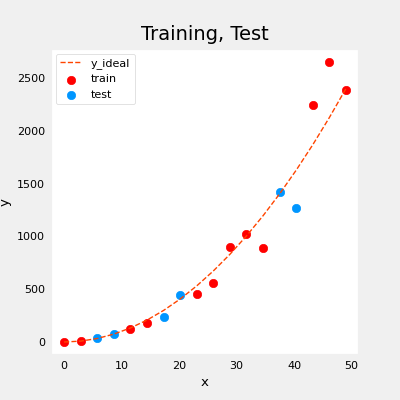

In [6]:
fig, ax = plt.subplots(1,1,figsize=(4,4))
ax.plot(x_ideal, y_ideal, "--", color = "orangered", label="y_ideal", lw=1)
ax.set_title("Training, Test",fontsize = 14)
ax.set_xlabel("x")
ax.set_ylabel("y")

ax.scatter(X_train, y_train, color = "red",           label="train")
ax.scatter(X_test, y_test,   color = dlc["dlblue"],   label="test")
ax.legend(loc='upper left')
plt.show()

<a name="2.2"></a>
### 2.2 Error calculation for model evaluation, linear regression 模型评估的误差计算：线性回归
When *evaluating* a linear regression model, you average the squared error difference of the predicted values and the target values.

在评估线性回归模型时，你需要计算预测值和目标值之间误差平方的平均值。

$$ J_\text{test}(\mathbf{w},b) = 
            \frac{1}{2m_\text{test}}\sum_{i=0}^{m_\text{test}-1} ( f_{\mathbf{w},b}(\mathbf{x}^{(i)}_\text{test}) - y^{(i)}_\text{test} )^2 
            \tag{1}
$$

<a name="ex01"></a>
### Exercise 1

Below, create a function to evaluate the error on a data set for a linear regression model.

下面，创建一个函数来评估线性回归模型在数据集上的误差。

In [11]:
# UNQ_C1
# GRADED CELL: eval_mse
def eval_mse(y, yhat):
    """ 
    Calculate the mean squared error on a data set.
    Args:
      y    : (ndarray  Shape (m,) or (m,1))  target value of each example
      yhat : (ndarray  Shape (m,) or (m,1))  predicted value of each example
    Returns:
      err: (scalar)             
    """
    m = len(y)
    err = 0.0
    for i in range(m):
    ### START CODE HERE ### 
      err+=(y[i]-yhat[i])**2
    err/= 2*m
    ### END CODE HERE ### 
    
    return(err)

In [12]:
y_hat = np.array([2.4, 4.2])
y_tmp = np.array([2.3, 4.1])
eval_mse(y_hat, y_tmp)

# BEGIN UNIT TEST
test_eval_mse(eval_mse)   
# END UNIT TEST

 All tests passed.


<details>
  <summary><font size="3" color="darkgreen"><b>Click for hints</b></font></summary>

    
```python
def eval_mse(y, yhat):
    """ 
    Calculate the mean squared error on a data set.
    Args:
      y    : (ndarray  Shape (m,) or (m,1))  target value of each example
      yhat : (ndarray  Shape (m,) or (m,1))  predicted value of each example
    Returns:
      err: (scalar)             
    """
    m = len(y)
    err = 0.0
    for i in range(m):
        err_i  = ( (yhat[i] - y[i])**2 ) 
        err   += err_i                                                                
    err = err / (2*m)                    
    return(err)
``` 

<a name="2.3"></a>
### 2.3 Compare performance on training and test data  比较训练数据和测试数据的性能
Let's build a high degree polynomial model to minimize training error. This will use the linear_regression functions from `sklearn`. The code is in the imported utility file if you would like to see the details. The steps below are:
让我们构建一个高次多项式模型来最小化训练误差。这将使用 `sklearn` 中的线性回归函数。如果您想查看详细信息，代码在导入的实用程序文件中。以下是步骤：
* create and fit the model. ('fit' is another name for training or running gradient descent).
* 创建并拟合模型。（“拟合”是训练或运行梯度下降的另一种说法）。
* compute the error on the training data.
* 计算训练数据上的误差。
* compute the error on the test data.
* 计算测试数据上的误差。

In [13]:
# create a model in sklearn, train on training data
degree = 10
lmodel = lin_model(degree)
lmodel.fit(X_train, y_train)

# predict on training data, find training error
yhat = lmodel.predict(X_train)
err_train = lmodel.mse(y_train, yhat)

# predict on test data, find error
yhat = lmodel.predict(X_test)
err_test = lmodel.mse(y_test, yhat)

The computed error on the training set is substantially less than that of the test set. 

训练集上的计算误差明显小于测试集上的计算误差。

In [14]:
print(f"training err {err_train:0.2f}, test err {err_test:0.2f}")

training err 58.01, test err 171215.01


The following plot shows why this is. The model fits the training data very well. To do so, it has created a complex function. The test data was not part of the training and the model does a poor job of predicting on this data.  

下面的图表解释了为什么会出现这种情况。模型非常好地拟合了训练数据。为了达到这个效果，它创建了一个复杂的函数。而测试数据并没有参与训练，模型在对这些数据进行预测时表现得很差。

This model would be described as 1) is overfitting, 2) has high variance 3) 'generalizes' poorly.

这个模型可以描述为：1) 过拟合，2) 方差高，3) “泛化”能力差。

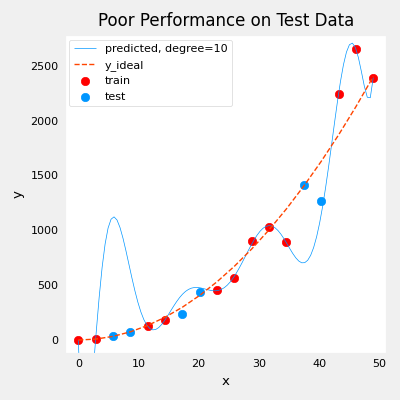

In [15]:
# plot predictions over data range 
x = np.linspace(0,int(X.max()),100)  # predict values for plot
y_pred = lmodel.predict(x).reshape(-1,1)

plt_train_test(X_train, y_train, X_test, y_test, x, y_pred, x_ideal, y_ideal, degree)

The test set error shows this model will not work well on new data. If you use the test error to guide improvements in the model, then the model will perform well on the test data... but the test data was meant to represent *new* data.

测试集误差表明该模型在新数据上表现不佳。如果你用测试误差来指导模型的改进，那么模型在测试数据上会表现良好…… 测试数据表示的是新数据。

You need yet another set of data to test new data performance.

你还需要另一组数据来测试模型在新数据上的性能。

The proposal made during lecture is to separate data into three groups. The distribution of training, cross-validation and test sets shown in the below table is a typical distribution, but can be varied depending on the amount of data available.

课程中提出的建议是将数据分为三组。下面表格中显示的训练集、交叉验证集和测试集的分布是一个典型的分布，但可以根据可用数据的数量进行调整。

| data             | % of total | Description |
|------------------|:----------:|:---------|
| training         | 60         | Data used to tune model parameters $w$ and $b$ in training or fitting |
| cross-validation | 20         | Data used to tune other model parameters like degree of polynomial, regularization or the architecture of a neural network.|
| test             | 20         | Data used to test the model after tuning to gauge performance on new data |


| 数据集             | 总占比(%) | 描述 |
|------------------|:----------:|:---------|
| 训练集         | 60         | 用于在训练或拟合过程中调整模型参数 $w$ 和 $b$ 的数据 |
| 交叉验证集 | 20         | 用于调整其他模型参数的数据，如多项式的次数、正则化或神经网络的架构。|
| 测试集             | 20         | 在调整参数后用于测试模型，以评估模型在新数据上的性能的数据 |

Let's generate three data sets below. We'll once again use `train_test_split` from `sklearn` but will call it twice to get three splits:

下面，我们将生成三个数据集。我们将再次使用 `sklearn` 中的 `train_test_split` 函数，但会调用两次以获得三个拆分：

In [16]:
# Generate  data
X,y, x_ideal,y_ideal = gen_data(40, 5, 0.7)
print("X.shape", X.shape, "y.shape", y.shape)

#split the data using sklearn routine 
X_train, X_, y_train, y_ = train_test_split(X,y,test_size=0.40, random_state=1)
X_cv, X_test, y_cv, y_test = train_test_split(X_,y_,test_size=0.50, random_state=1)
print("X_train.shape", X_train.shape, "y_train.shape", y_train.shape)
print("X_cv.shape", X_cv.shape, "y_cv.shape", y_cv.shape)
print("X_test.shape", X_test.shape, "y_test.shape", y_test.shape)

X.shape (40,) y.shape (40,)
X_train.shape (24,) y_train.shape (24,)
X_cv.shape (8,) y_cv.shape (8,)
X_test.shape (8,) y_test.shape (8,)


<a name="3"></a>
## 3 - Bias and Variance（偏差和方差）<img align="Right" src="./images/C2_W3_BiasVarianceDegree.png"  style=" width:500px; padding: 10px 20px ; "> 
 Above, it was clear the degree of the polynomial model was too high. How can you choose a good value? It turns out, as shown in the diagram, the training and cross-validation performance can provide guidance. By trying a range of degree values, the training and cross-validation performance can be evaluated. As the degree becomes too large, the cross-validation performance will start to degrade relative to the training performance. Let's try this on our example.
 
 上面已经清楚地表明，多项式模型的次数太高了。那么如何选择一个合适的值呢？事实证明，如图表所示，训练集和交叉验证集的性能可以提供指导。通过尝试一系列的次数值，可以评估训练集和交叉验证集的性能。当次数过大时，交叉验证集的性能相对于训练集的性能会开始下降。让我们在示例中尝试一下。

<a name="3.1"></a>
### 3.1 Plot Train, Cross-Validation, Test  绘制训练集、交叉验证集和测试集
You can see below the datapoints that will be part of training (in red) are intermixed with those that the model is not trained on (test and cv).

您可以在下面看到，属于训练集的数据点（红色）与模型未进行训练的数据点（测试集和交叉验证集）是混合在一起的。

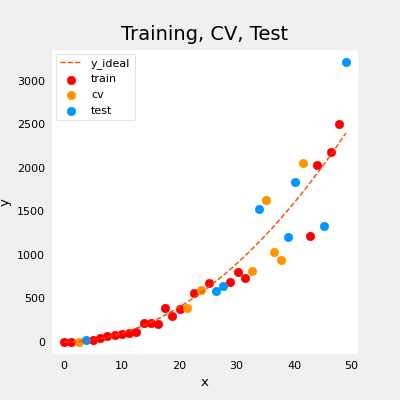

In [17]:
fig, ax = plt.subplots(1,1,figsize=(4,4))
ax.plot(x_ideal, y_ideal, "--", color = "orangered", label="y_ideal", lw=1)
ax.set_title("Training, CV, Test",fontsize = 14)
ax.set_xlabel("x")
ax.set_ylabel("y")

ax.scatter(X_train, y_train, color = "red",           label="train")
ax.scatter(X_cv, y_cv,       color = dlc["dlorange"], label="cv")
ax.scatter(X_test, y_test,   color = dlc["dlblue"],   label="test")
ax.legend(loc='upper left')
plt.show()

<a name="3.2"></a>
### 3.2 Finding the optimal degree  寻找最佳degree
In previous labs, you found that you could create a model capable of fitting complex curves by utilizing a polynomial (See Course1, Week2 Feature Engineering and Polynomial Regression Lab).  Further, you demonstrated that by increasing the *degree* of the polynomial, you could *create* overfitting. (See Course 1, Week3, Over-Fitting Lab). Let's use that knowledge here to test our ability to tell the difference between over-fitting and under-fitting.

在之前的实验中，您发现通过使用多项式可以创建一个能够拟合复杂曲线的模型（参见课程1，第2周的特征工程和多项式回归实验）。此外，你还证明了通过增加多项式的次数，可以造成过拟合（参见课程1，第3周的过拟合实验）。让我们在这里利用这些知识来测试我们区分过拟合和欠拟合的能力。

Let's train the model repeatedly, increasing the degree of the polynomial each iteration. Here, we're going to use the [scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html#sklearn.linear_model.LinearRegression) linear regression model for speed and simplicity.

让我们反复训练模型，每次迭代都增加多项式的次数。在这里，为了速度和简洁性，我们将使用 [scikit-learn] 的线性回归模型。

In [18]:
max_degree = 9
err_train = np.zeros(max_degree)    
err_cv = np.zeros(max_degree)      
x = np.linspace(0,int(X.max()),100)  
y_pred = np.zeros((100,max_degree))  #columns are lines to plot

for degree in range(max_degree):
    lmodel = lin_model(degree+1)
    lmodel.fit(X_train, y_train)
    yhat = lmodel.predict(X_train)
    err_train[degree] = lmodel.mse(y_train, yhat)
    yhat = lmodel.predict(X_cv)
    err_cv[degree] = lmodel.mse(y_cv, yhat)
    y_pred[:,degree] = lmodel.predict(x)
    
optimal_degree = np.argmin(err_cv)+1

<font size="4">Let's plot the result:</font>

让我们绘制结果图：

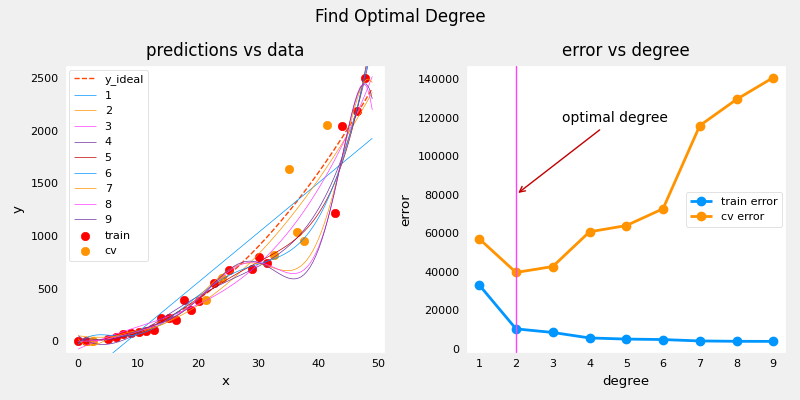

In [20]:
plt.close("all")
plt_optimal_degree(X_train, y_train, X_cv, y_cv, x, y_pred, x_ideal, y_ideal, 
                   err_train, err_cv, optimal_degree, max_degree)

The plot above demonstrates that separating data into two groups, data the model is trained on and data the model has not been trained on, can be used to determine if the model is underfitting or overfitting. In our example, we created a variety of models varying from underfitting to overfitting by increasing the degree of the polynomial used. 
- On the left plot, the solid lines represent the predictions from these models. A polynomial model with degree 1 produces a straight line that intersects very few data points, while the maximum degree hews very closely to every data point. 
- on the right:
    - the error on the trained data (blue) decreases as the model complexity increases as expected
    - the error of the cross-validation data decreases initially as the model starts to conform to the data, but then increases as the model starts to over-fit on the training data (fails to *generalize*).     
    
It's worth noting that the curves in these examples as not as smooth as one might draw for a lecture. It's clear the specific data points assigned to each group can change your results significantly. The general trend is what is important.


上面的图表表明，通过将数据分为两组——模型训练所用的数据和模型未训练的数据——可以用来判断模型是欠拟合还是过拟合。在我们的例子中，我们通过增加所用多项式的次数，创建了从欠拟合到过拟合的各种模型。
-  在左侧图表中，实线代表这些模型的预测结果。一次多项式模型产生一条直线，与很少的数据点相交，而最高次数多项式则非常紧密地贴合每一个数据点。
-  在右侧图表中：
    - 如预期所料，随着模型复杂度的增加，训练数据上的误差（蓝色）逐渐减小。
    - 交叉验证数据的误差起初随着模型开始符合数据而减小，但随后随着模型开始在训练数据上过拟合（即未能泛化）而增加。
    
值得注意的是，这些示例中的曲线并不像课程中可能画出的那样平滑。显然，分配给每个组的具体数据点会显著改变结果。重要的是要关注总体趋势。

<a name="3.3"></a>
### 3.3 Tuning Regularization. 调整正则化参数
In previous labs, you have utilized *regularization* to reduce overfitting. Similar to degree, one can use the same methodology to tune the regularization parameter lambda ($\lambda$).

Let's demonstrate this by starting with a high degree polynomial and varying the regularization parameter.


在之前的实验中，您已经利用正则化来减少过拟合。与次数类似，我们可以使用相同的方法来调整正则化参数 $\lambda$ 。

让我们通过从一个高次数多项式开始并改变正则化参数来演示这一点。

In [21]:
lambda_range = np.array([0.0, 1e-6, 1e-5, 1e-4,1e-3,1e-2, 1e-1,1,10,100])
num_steps = len(lambda_range)
degree = 10
err_train = np.zeros(num_steps)    
err_cv = np.zeros(num_steps)       
x = np.linspace(0,int(X.max()),100) 
y_pred = np.zeros((100,num_steps))  #columns are lines to plot

for i in range(num_steps):
    lambda_= lambda_range[i]
    lmodel = lin_model(degree, regularization=True, lambda_=lambda_)
    lmodel.fit(X_train, y_train)
    yhat = lmodel.predict(X_train)
    err_train[i] = lmodel.mse(y_train, yhat)
    yhat = lmodel.predict(X_cv)
    err_cv[i] = lmodel.mse(y_cv, yhat)
    y_pred[:,i] = lmodel.predict(x)
    
optimal_reg_idx = np.argmin(err_cv) 

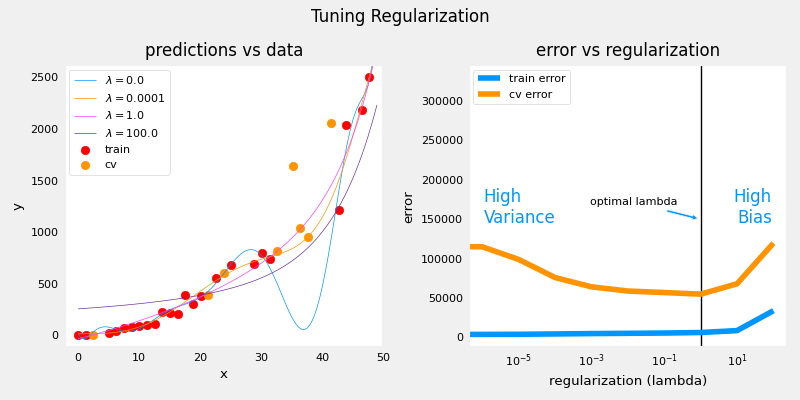

In [22]:
plt.close("all")
plt_tune_regularization(X_train, y_train, X_cv, y_cv, x, y_pred, err_train, err_cv, optimal_reg_idx, lambda_range)

Above, the plots show that as regularization increases, the model moves from a high variance (overfitting) model to a high bias (underfitting) model. The vertical line in the right plot shows the optimal value of lambda. In this example, the polynomial degree was set to 10. 

上面，图表显示，随着正则化强度的增加，模型从高方差（过拟合）模型转变为高偏差（欠拟合）模型。右图中的垂直线显示了λ（lambda）的最优值。在这个例子中，多项式的次数被设置为10。

<a name="3.4"></a>
### 3.4 Getting more data: Increasing Training Set Size (m)  获取更多数据：增加训练集大小（m）
When a model is overfitting (high variance), collecting additional data can improve performance. Let's try that here.

当模型出现过拟合（高方差）时，收集更多数据可以提高性能。让我们在这里尝试一下。

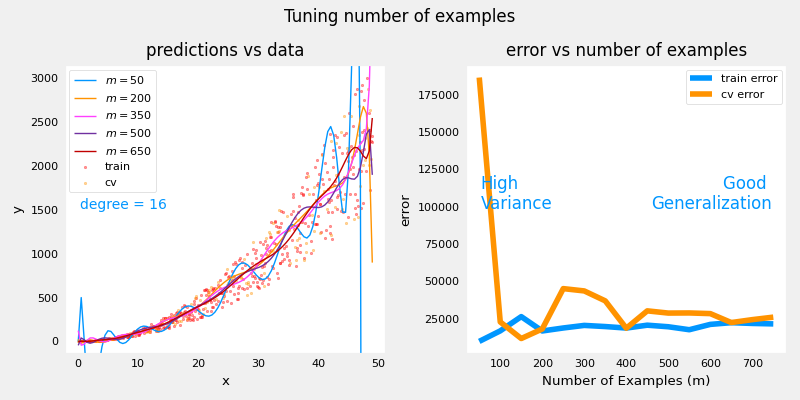

In [23]:
X_train, y_train, X_cv, y_cv, x, y_pred, err_train, err_cv, m_range,degree = tune_m()
plt_tune_m(X_train, y_train, X_cv, y_cv, x, y_pred, err_train, err_cv, m_range, degree)

The above plots show that when a model has high variance and is overfitting, adding more examples improves performance. Note the curves on the left plot. The final curve with the highest value of $m$ is a smooth curve that is in the center of the data. On the right, as the number of examples increases, the performance of the training set and cross-validation set converge to similar values. Note that the curves are not as smooth as one might see in a lecture. That is to be expected. The trend remains clear: more data improves generalization. 

> Note that adding more examples when the model has high bias (underfitting) does not improve performance.


上述图表显示，当模型具有高方差且出现过拟合时，增加更多示例可以提高性能。请注意左侧图表中的曲线。具有最高 $m$ 值的最终曲线是一条平滑曲线，位于数据中心。在右侧图表中，随着示例数量的增加，训练集和交叉验证集的性能收敛到相似值。请注意，这些曲线并不像讲座中看到的那样平滑。这是预料之中的。趋势仍然清晰：更多数据可以改善泛化能力。

> 注意，当模型具有高偏差（欠拟合）时，增加更多示例并不能提高性能。


<a name="4"></a>
## 4 - Evaluating a Learning Algorithm (Neural Network)  评估学习算法（神经网络）
Above, you tuned aspects of a polynomial regression model. Here, you will work with a neural network model. Let's start by creating a classification data set.

上面，您调整了多项式回归模型的各个方面。在这里，您将使用神经网络模型。让我们首先从创建一个分类数据集开始。

<a name="4.1"></a>
### 4.1 Data Set  数据集
Run the cell below to generate a data set and split it into training, cross-validation (CV) and test sets. In this example, we're increasing the percentage of cross-validation data points for emphasis.  

运行下面的单元格以生成一个数据集，并将其分为训练集、交叉验证（CV）集和测试集。在这个例子中，为了强调，我们增加了交叉验证数据点的百分比。

In [24]:
# Generate and split data set
X, y, centers, classes, std = gen_blobs()

# split the data. Large CV population for demonstration
X_train, X_, y_train, y_ = train_test_split(X,y,test_size=0.50, random_state=1)
X_cv, X_test, y_cv, y_test = train_test_split(X_,y_,test_size=0.20, random_state=1)
print("X_train.shape:", X_train.shape, "X_cv.shape:", X_cv.shape, "X_test.shape:", X_test.shape)

X_train.shape: (400, 2) X_cv.shape: (320, 2) X_test.shape: (80, 2)


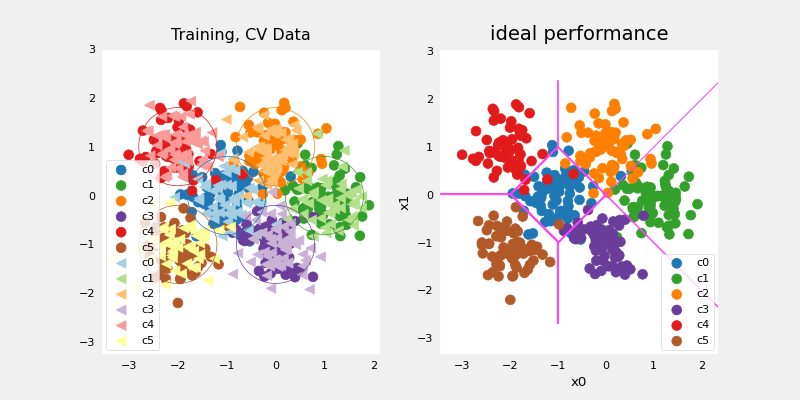

In [25]:
plt_train_eq_dist(X_train, y_train,classes, X_cv, y_cv, centers, std)

Above, you can see the data on the left. There are six clusters identified by color. Both training points (dots) and cross-validataion points (triangles) are shown. The interesting points are those that fall in ambiguous locations where either cluster might consider them members. What would you expect a neural network model to do? What would be an example of overfitting? underfitting?  

在左侧，您可以看到数据。数据中有六个通过颜色区分的集群。图中既显示了训练点（圆点），也显示了交叉验证点（三角形）。有趣的点是那些位于模糊位置、两个集群都可能将其视为成员的点。您期望神经网络模型会怎么做？过拟合和欠拟合的例子分别是什么？

On the right is an example of an 'ideal' model, or a model one might create knowing the source of the data. The lines represent 'equal distance' boundaries where the distance between center points is equal. It's worth noting that this model would "misclassify" roughly 8% of the total data set.

在右侧是一个“理想”模型的例子，或者是一个在了解数据来源的情况下可能创建的模型。线条表示“等距”边界，即中心点之间的距离相等。值得注意的是，该模型将“错误分类”大约8%的总数据集。

<a name="4.2"></a>
### 4.2 Evaluating categorical model by calculating classification error  通过计算分类错误率来评估分类模型
The evaluation function for categorical models used here is simply the fraction of incorrect predictions:  

这里使用的分类模型评估函数仅仅是错误预测的比例：

$$ J_{cv} =\frac{1}{m}\sum_{i=0}^{m-1} 
\begin{cases}
    1, & \text{if $\hat{y}^{(i)} \neq y^{(i)}$}\\
    0, & \text{otherwise}
\end{cases}
$$

<a name="ex02"></a>
### Exercise 2

Below, complete the routine to calculate classification error. Note, in this lab, target values are the index of the category and are not [one-hot encoded](https://en.wikipedia.org/wiki/One-hot).

下面，请完成计算分类错误的程序。请注意，在这个实验中，目标值是类别的索引，而不是独热编码（one-hot encoded）。

In [26]:
# UNQ_C2
# GRADED CELL: eval_cat_err
def eval_cat_err(y, yhat):
    """ 
    Calculate the categorization error
    Args:
      y    : (ndarray  Shape (m,) or (m,1))  target value of each example
      yhat : (ndarray  Shape (m,) or (m,1))  predicted value of each example
    Returns:|
      cerr: (scalar)             
    """
    m = len(y)
    incorrect = 0
    for i in range(m):
    ### START CODE HERE ### 
      if(yhat[i]!=y[i]):
             incorrect+=1
    cerr=incorrect/m    
    ### END CODE HERE ### 
    
    return(cerr)

In [19]:
y_hat = np.array([1, 2, 0])
y_tmp = np.array([1, 2, 3])
print(f"categorization error {np.squeeze(eval_cat_err(y_hat, y_tmp)):0.3f}, expected:0.333" )
y_hat = np.array([[1], [2], [0], [3]])
y_tmp = np.array([[1], [2], [1], [3]])
print(f"categorization error {np.squeeze(eval_cat_err(y_hat, y_tmp)):0.3f}, expected:0.250" )

# BEGIN UNIT TEST  
test_eval_cat_err(eval_cat_err)
# END UNIT TEST
# BEGIN UNIT TEST  
test_eval_cat_err(eval_cat_err)
# END UNIT TEST

categorization error 0.333, expected:0.333
categorization error 0.250, expected:0.250
 All tests passed.
 All tests passed.


<details>
  <summary><font size="3" color="darkgreen"><b>Click for hints</b></font></summary>
    
```python
def eval_cat_err(y, yhat):
    """ 
    Calculate the categorization error
    Args:
      y    : (ndarray  Shape (m,) or (m,1))  target value of each example
      yhat : (ndarray  Shape (m,) or (m,1))  predicted value of each example
    Returns:|
      cerr: (scalar)             
    """
    m = len(y)
    incorrect = 0
    for i in range(m):
        if yhat[i] != y[i]:    # @REPLACE
            incorrect += 1     # @REPLACE
    cerr = incorrect/m         # @REPLACE
    return(cerr)                                    
``` 

<a name="5"></a>
## 5 - Model Complexity 模型复杂度
Below, you will build two models. A complex model and a simple model. You will evaluate the models to determine if they are likely to overfit or underfit.

下面，您将构建两个模型：一个复杂模型和一个简单模型。您将评估这些模型，以确定它们是否可能出现过拟合或欠拟合。

###  5.1 Complex model  复杂模型
 
<a name="ex03"></a>
### Exercise 3
Below, compose a three-layer model (下面，请构建一个三层模型):
* Dense layer with 120 units, relu activation
* 密集层（Dense layer），包含120个单元，使用relu激活函数
* Dense layer with 40 units, relu activation
* 密集层，包含40个单元，使用relu激活函数
* Dense layer with 6 units and a linear activation (not softmax) 
* 密集层，包含6个单元，使用线性激活函数（不是softmax）
Compile using

编译时，请使用：
* loss with `SparseCategoricalCrossentropy`, remember to use  `from_logits=True`
* 损失函数为 `SparseCategoricalCrossentropy`，记得设置 `from_logits=True`
* Adam optimizer with learning rate of 0.01.
* 优化器为Adam，学习率设置为0.01

In [36]:
# UNQ_C3
# GRADED CELL: model
import logging
logging.getLogger("tensorflow").setLevel(logging.ERROR)

tf.random.set_seed(1234)
model = Sequential(
    [
        ### START CODE HERE ### 
        Dense(120, activation = 'relu', name = "L1"),      
        Dense(40, activation = 'relu', name = "L2"),         
        Dense(6, activation = 'linear', name = "L3") 
        ### END CODE HERE ### 
    ], name="Complex"
)
model.compile(
    ### START CODE HERE ### 
    loss=SparseCategoricalCrossentropy(from_logits=True),
    optimizer=tf.keras.optimizers.Adam(lr=0.01),
    ### END CODE HERE ### 
)

In [37]:
# BEGIN UNIT TEST
model.fit(
    X_train, y_train,
    epochs=1000
)
# END UNIT TEST

Epoch 1/1000
13/13 [==============================] - 0s 3ms/step - loss: 1.1106
Epoch 2/1000
13/13 [==============================] - 0s 3ms/step - loss: 0.4281
Epoch 3/1000
13/13 [==============================] - 0s 3ms/step - loss: 0.3345
Epoch 4/1000
13/13 [==============================] - 0s 3ms/step - loss: 0.2896
Epoch 5/1000
13/13 [==============================] - 0s 3ms/step - loss: 0.2867
Epoch 6/1000
13/13 [==============================] - 0s 3ms/step - loss: 0.2918
Epoch 7/1000
13/13 [==============================] - 0s 3ms/step - loss: 0.2497
Epoch 8/1000
13/13 [==============================] - 0s 3ms/step - loss: 0.2298
Epoch 9/1000
13/13 [==============================] - 0s 3ms/step - loss: 0.2307
Epoch 10/1000
13/13 [==============================] - 0s 3ms/step - loss: 0.2071
Epoch 11/1000
13/13 [==============================] - 0s 3ms/step - loss: 0.2115
Epoch 12/1000
13/13 [==============================] - 0s 3ms/step - loss: 0.2070
Epoch 13/1000
13/13 [====

In [39]:
# BEGIN UNIT TEST
model.summary()

model_test(model, classes, X_train.shape[1]) 
# END UNIT TEST


Model: "Complex"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
L1 (Dense)                   (None, 120)               360       
_________________________________________________________________
L2 (Dense)                   (None, 40)                4840      
_________________________________________________________________
L3 (Dense)                   (None, 6)                 246       
Total params: 5,446
Trainable params: 5,446
Non-trainable params: 0
_________________________________________________________________
All tests passed!


<details>
  <summary><font size="3" color="darkgreen"><b>Click for hints</b></font></summary>
    
Summary should match this (layer instance names may increment )
```
Model: "Complex"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
=================================================================
L1 (Dense)                   (None, 120)               360       
_________________________________________________________________
L2 (Dense)                   (None, 40)                4840      
_________________________________________________________________
L3 (Dense)                   (None, 6)                 246       
=================================================================
Total params: 5,446
Trainable params: 5,446
Non-trainable params: 0
_________________________________________________________________
```
  <details>
  <summary><font size="3" color="darkgreen"><b>Click for more hints</b></font></summary>
  
```python
tf.random.set_seed(1234)
model = Sequential(
    [
        Dense(120, activation = 'relu', name = "L1"),      
        Dense(40, activation = 'relu', name = "L2"),         
        Dense(classes, activation = 'linear', name = "L3")  
    ], name="Complex"
)
model.compile(
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),          
    optimizer=tf.keras.optimizers.Adam(0.01),   
)

model.fit(
    X_train,y_train,
    epochs=1000
)                                  
``` 

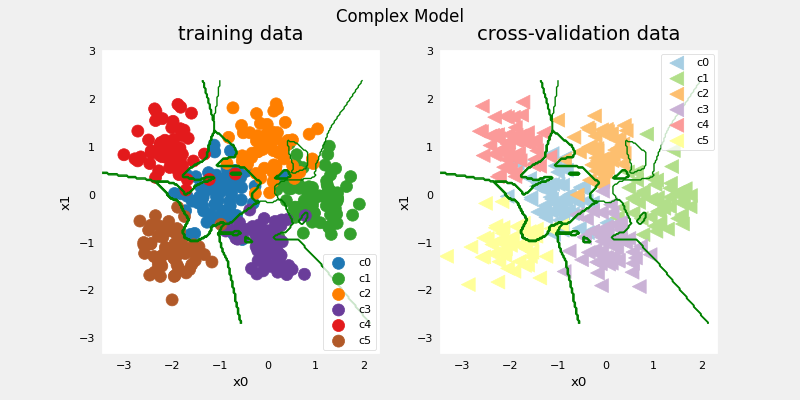

In [40]:
#make a model for plotting routines to call
model_predict = lambda Xl: np.argmax(tf.nn.softmax(model.predict(Xl)).numpy(),axis=1)
plt_nn(model_predict,X_train,y_train, classes, X_cv, y_cv, suptitle="Complex Model")

This model has worked very hard to capture outliers of each category. As a result, it has miscategorized some of the cross-validation data. Let's calculate the classification error.

这个模型非常努力地捕捉每个类别的离群点。结果，它错误地分类了一些交叉验证数据。让我们来计算一下分类错误率。

In [41]:
training_cerr_complex = eval_cat_err(y_train, model_predict(X_train))
cv_cerr_complex = eval_cat_err(y_cv, model_predict(X_cv))
print(f"categorization error, training, complex model: {training_cerr_complex:0.3f}")
print(f"categorization error, cv,       complex model: {cv_cerr_complex:0.3f}")

categorization error, training, complex model: 0.003
categorization error, cv,       complex model: 0.122


<a name="5.1"></a>
### 5.1 Simple model  简单模型
Now, let's try a simple model

现在，让我们尝试一个简单模型。

<a name="ex04"></a>
### Exercise 4

Below, compose a two-layer model (下面，请构建一个两层模型):
* Dense layer with 6 units, relu activation
* 密集层（Dense layer），包含6个单元，使用relu激活函数
* Dense layer with 6 units and a linear activation. 
* 密集层，包含6个单元，使用线性激活函数
Compile using  编译时，请使用：
* loss with `SparseCategoricalCrossentropy`, remember to use  `from_logits=True`
* 损失函数为`SparseCategoricalCrossentropy`，记得设置 `from_logits=True`
* Adam optimizer with learning rate of 0.01.
* 优化器为Adam，学习率设置为0.01

In [42]:
# UNQ_C4
# GRADED CELL: model_s

tf.random.set_seed(1234)
model_s = Sequential(
    [
        ### START CODE HERE ### 
        Dense(6, activation = 'relu', name="L1"),   
        Dense(classes, activation = 'linear', name="L2")
        ### END CODE HERE ### 
    ], name = "Simple"
)
model_s.compile(
    ### START CODE HERE ### 
    loss=SparseCategoricalCrossentropy(from_logits=True),
    optimizer=tf.keras.optimizers.Adam(lr=0.01),
    ### START CODE HERE ### 
)


In [43]:
import logging
logging.getLogger("tensorflow").setLevel(logging.ERROR)

# BEGIN UNIT TEST
model_s.fit(
    X_train,y_train,
    epochs=1000
)
# END UNIT TEST

Epoch 1/1000
13/13 [==============================] - 0s 2ms/step - loss: 1.7306
Epoch 2/1000
13/13 [==============================] - 0s 2ms/step - loss: 1.4468
Epoch 3/1000
13/13 [==============================] - 0s 2ms/step - loss: 1.2902
Epoch 4/1000
13/13 [==============================] - 0s 2ms/step - loss: 1.1367
Epoch 5/1000
13/13 [==============================] - 0s 2ms/step - loss: 0.9710
Epoch 6/1000
13/13 [==============================] - 0s 2ms/step - loss: 0.7947
Epoch 7/1000
13/13 [==============================] - 0s 2ms/step - loss: 0.6499
Epoch 8/1000
13/13 [==============================] - 0s 2ms/step - loss: 0.5378
Epoch 9/1000
13/13 [==============================] - 0s 2ms/step - loss: 0.4652
Epoch 10/1000
13/13 [==============================] - 0s 2ms/step - loss: 0.4184
Epoch 11/1000
13/13 [==============================] - 0s 2ms/step - loss: 0.3860
Epoch 12/1000
13/13 [==============================] - 0s 2ms/step - loss: 0.3641
Epoch 13/1000
13/13 [====

In [44]:
# BEGIN UNIT TEST
model_s.summary()

model_s_test(model_s, classes, X_train.shape[1])
# END UNIT TEST

Model: "Simple"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
L1 (Dense)                   (None, 6)                 18        
_________________________________________________________________
L2 (Dense)                   (None, 6)                 42        
Total params: 60
Trainable params: 60
Non-trainable params: 0
_________________________________________________________________
All tests passed!


<details>
  <summary><font size="3" color="darkgreen"><b>Click for hints</b></font></summary>
    
Summary should match this (layer instance names may increment )
```
Model: "Simple"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
=================================================================
L1 (Dense)                   (None, 6)                 18        
_________________________________________________________________
L2 (Dense)                   (None, 6)                 42        
=================================================================
Total params: 60
Trainable params: 60
Non-trainable params: 0
_________________________________________________________________
```
  <details>
  <summary><font size="3" color="darkgreen"><b>Click for more hints</b></font></summary>
  
```python
tf.random.set_seed(1234)
model_s = Sequential(
    [
        Dense(6, activation = 'relu', name="L1"),            # @REPLACE
        Dense(classes, activation = 'linear', name="L2")     # @REPLACE
    ], name = "Simple"
)
model_s.compile(
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),     # @REPLACE
    optimizer=tf.keras.optimizers.Adam(0.01),     # @REPLACE
)

model_s.fit(
    X_train,y_train,
    epochs=1000
)                                   
``` 

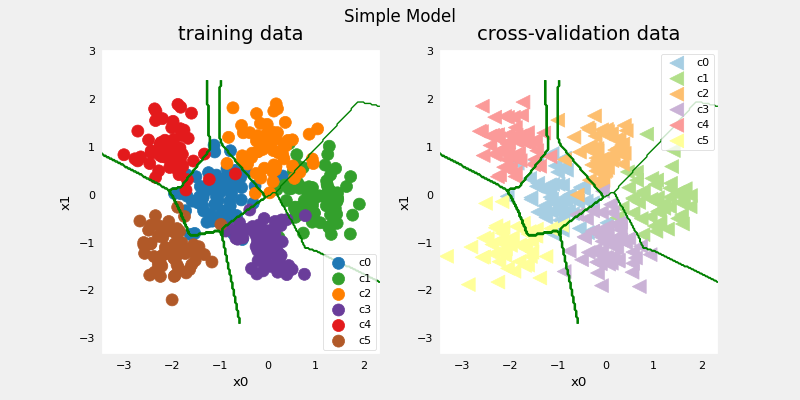

In [45]:
#make a model for plotting routines to call
model_predict_s = lambda Xl: np.argmax(tf.nn.softmax(model_s.predict(Xl)).numpy(),axis=1)
plt_nn(model_predict_s,X_train,y_train, classes, X_cv, y_cv, suptitle="Simple Model")

This simple models does pretty well. Let's calculate the classification error.

这个简单模型表现得相当不错。让我们来计算一下分类错误率。

In [56]:
training_cerr_simple = eval_cat_err(y_train, model_predict_s(X_train))
cv_cerr_simple = eval_cat_err(y_cv, model_predict_s(X_cv))
print(f"categorization error, training, simple model, {training_cerr_simple:0.3f}, complex model: {training_cerr_complex:0.3f}" )
print(f"categorization error, cv,       simple model, {cv_cerr_simple:0.3f}, complex model: {cv_cerr_complex:0.3f}" )

categorization error, training, simple model, 0.062, complex model: 0.003
categorization error, cv,       simple model, 0.087, complex model: 0.122


Our simple model has a little higher classification error on training data but does better on cross-validation data than the more complex model.

我们的简单模型在训练数据上的分类错误率稍高一些，但在交叉验证数据上的表现却比复杂模型更好。

<a name="6"></a>
## 6 - Regularization 正则化
As in the case of polynomial regression, one can apply regularization to moderate the impact of a more complex model. Let's try this below.

与多项式回归一样，我们可以应用正则化来减轻复杂模型的影响。下面让我们来尝试一下。

<a name="ex05"></a>
### Exercise 5

Reconstruct your complex model, but this time include regularization.

重新构建您的复杂模型，但这次要包含正则化。

Below, compose a three-layer model:

下面，请构建一个三层模型：

* Dense layer with 120 units, relu activation, `kernel_regularizer=tf.keras.regularizers.l2(0.1)`
* 密集层（Dense layer），包含120个单元，使用relu激活函数，并设置 `kernel_regularizer=tf.keras.regularizers.l2(0.1)`
* Dense layer with 40 units, relu activation, `kernel_regularizer=tf.keras.regularizers.l2(0.1)`
* 密集层，包含40个单元，使用relu激活函数，并设置 `kernel_regularizer=tf.keras.regularizers.l2(0.1)`
* Dense layer with 6 units and a linear activation. 
* 密集层，包含6个单元，使用线性激活函数
Compile using
编译时，请使用：
* loss with `SparseCategoricalCrossentropy`, remember to use  `from_logits=True`
* 损失函数为 `SparseCategoricalCrossentropy`，记得设置 `from_logits=True`
* Adam optimizer with learning rate of 0.01.
* 优化器为Adam，学习率设置为0.01

In [47]:
# UNQ_C5
# GRADED CELL: model_r

tf.random.set_seed(1234)
model_r = Sequential(
    [
        ### START CODE HERE ### 
        Dense(120, activation = 'relu', kernel_regularizer=tf.keras.regularizers.l2(0.1), name="L1"), 
        Dense(40, activation = 'relu', kernel_regularizer=tf.keras.regularizers.l2(0.1), name="L2"),  
        Dense(classes, activation = 'linear', name="L3")
        ### START CODE HERE ### 
    ], name= "ComplexRegularized"
)
model_r.compile(
    ### START CODE HERE ### 
    loss=SparseCategoricalCrossentropy(from_logits=True),
    optimizer=tf.keras.optimizers.Adam(lr=0.01),
    ### START CODE HERE ### 
)


In [48]:
# BEGIN UNIT TEST
model_r.fit(
    X_train, y_train,
    epochs=1000
)
# END UNIT TEST

Epoch 1/1000
13/13 [==============================] - 0s 3ms/step - loss: 4.4464
Epoch 2/1000
13/13 [==============================] - 0s 3ms/step - loss: 1.7086
Epoch 3/1000
13/13 [==============================] - 0s 3ms/step - loss: 1.3465
Epoch 4/1000
13/13 [==============================] - 0s 3ms/step - loss: 1.0870
Epoch 5/1000
13/13 [==============================] - 0s 3ms/step - loss: 1.0137
Epoch 6/1000
13/13 [==============================] - 0s 3ms/step - loss: 0.9718
Epoch 7/1000
13/13 [==============================] - ETA: 0s - loss: 1.105 - 0s 3ms/step - loss: 0.9481
Epoch 8/1000
13/13 [==============================] - 0s 3ms/step - loss: 0.8934
Epoch 9/1000
13/13 [==============================] - 0s 3ms/step - loss: 0.8171
Epoch 10/1000
13/13 [==============================] - 0s 3ms/step - loss: 0.7715
Epoch 11/1000
13/13 [==============================] - 0s 3ms/step - loss: 0.7611
Epoch 12/1000
13/13 [==============================] - 0s 3ms/step - loss: 0.7521
E

In [53]:
# BEGIN UNIT TEST
model_r.summary()

model_r_test(model_r, classes, X_train.shape[1]) 
# END UNIT TEST

Model: "ComplexRegularized"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
L1 (Dense)                   (None, 120)               360       
_________________________________________________________________
L2 (Dense)                   (None, 40)                4840      
_________________________________________________________________
L3 (Dense)                   (None, 6)                 246       
Total params: 5,446
Trainable params: 5,446
Non-trainable params: 0
_________________________________________________________________
ddd
All tests passed!


<details>
  <summary><font size="3" color="darkgreen"><b>Click for hints</b></font></summary>
    
Summary should match this (layer instance names may increment )
```
Model: "ComplexRegularized"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
=================================================================
L1 (Dense)                   (None, 120)               360       
_________________________________________________________________
L2 (Dense)                   (None, 40)                4840      
_________________________________________________________________
L3 (Dense)                   (None, 6)                 246       
=================================================================
Total params: 5,446
Trainable params: 5,446
Non-trainable params: 0
_________________________________________________________________
```
  <details>
  <summary><font size="3" color="darkgreen"><b>Click for more hints</b></font></summary>
  
```python
tf.random.set_seed(1234)
model_r = Sequential(
    [
        Dense(120, activation = 'relu', kernel_regularizer=tf.keras.regularizers.l2(0.1), name="L1"), 
        Dense(40, activation = 'relu', kernel_regularizer=tf.keras.regularizers.l2(0.1), name="L2"),  
        Dense(classes, activation = 'linear', name="L3")  
    ], name="ComplexRegularized"
)
model_r.compile(
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True), 
    optimizer=tf.keras.optimizers.Adam(0.01),                             
)

model_r.fit(
    X_train,y_train,
    epochs=1000
)                                   
``` 

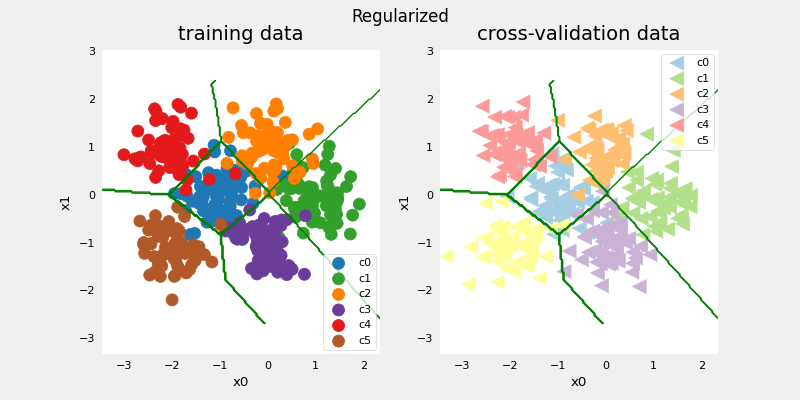

In [54]:
#make a model for plotting routines to call
model_predict_r = lambda Xl: np.argmax(tf.nn.softmax(model_r.predict(Xl)).numpy(),axis=1)
 
plt_nn(model_predict_r, X_train,y_train, classes, X_cv, y_cv, suptitle="Regularized")

The results look very similar to the 'ideal' model. Let's check classification error.

结果与“理想”模型非常相似。让我们来检查一下分类错误率。

In [58]:
training_cerr_reg = eval_cat_err(y_train, model_predict_r(X_train))
cv_cerr_reg = eval_cat_err(y_cv, model_predict_r(X_cv))
test_cerr_reg = eval_cat_err(y_test, model_predict_r(X_test))
print(f"categorization error, training, regularized: {training_cerr_reg:0.3f}, simple model, {training_cerr_simple:0.3f}, complex model: {training_cerr_complex:0.3f}" )
print(f"categorization error, cv,       regularized: {cv_cerr_reg:0.3f}, simple model, {cv_cerr_simple:0.3f}, complex model: {cv_cerr_complex:0.3f}" )

categorization error, training, regularized: 0.072, simple model, 0.062, complex model: 0.003
categorization error, cv,       regularized: 0.066, simple model, 0.087, complex model: 0.122


The simple model is a bit better in the training set than the regularized model but it worse in the cross validation set.

简单模型在训练集上的表现比正则化模型略好一些，但在交叉验证集上的表现却更差。

<a name="7"></a>
## 7 - Iterate to find optimal regularization value 迭代寻找最佳正则化值
As you did in linear regression, you can try many regularization values. This code takes several minutes to run. If you have time, you can run it and check the results. If not, you have completed the graded parts of the assignment!

就像你在线性回归中所做的那样，你可以尝试许多不同的正则化值。这段代码的运行需要几分钟的时间。如果你有时间，可以运行它并检查结果。如果没有，你已经完成了本次作业中需要评分的部分！

In [59]:
tf.random.set_seed(1234)
lambdas = [0.0, 0.001, 0.01, 0.05, 0.1, 0.2, 0.3]
models=[None] * len(lambdas)
for i in range(len(lambdas)):
    lambda_ = lambdas[i]
    models[i] =  Sequential(
        [
            Dense(120, activation = 'relu', kernel_regularizer=tf.keras.regularizers.l2(lambda_)),
            Dense(40, activation = 'relu', kernel_regularizer=tf.keras.regularizers.l2(lambda_)),
            Dense(classes, activation = 'linear')
        ]
    )
    models[i].compile(
        loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
        optimizer=tf.keras.optimizers.Adam(0.01),
    )

    models[i].fit(
        X_train,y_train,
        epochs=1000
    )
    print(f"Finished lambda = {lambda_}")


Epoch 1/1000
13/13 [==============================] - 0s 3ms/step - loss: 1.1106
Epoch 2/1000
13/13 [==============================] - 0s 3ms/step - loss: 0.4281
Epoch 3/1000
13/13 [==============================] - 0s 3ms/step - loss: 0.3345
Epoch 4/1000
13/13 [==============================] - 0s 3ms/step - loss: 0.2896
Epoch 5/1000
13/13 [==============================] - 0s 3ms/step - loss: 0.2867
Epoch 6/1000
13/13 [==============================] - 0s 3ms/step - loss: 0.2918
Epoch 7/1000
13/13 [==============================] - 0s 3ms/step - loss: 0.2497
Epoch 8/1000
13/13 [==============================] - 0s 3ms/step - loss: 0.2298
Epoch 9/1000
13/13 [==============================] - 0s 3ms/step - loss: 0.2307
Epoch 10/1000
13/13 [==============================] - 0s 3ms/step - loss: 0.2071
Epoch 11/1000
13/13 [==============================] - 0s 3ms/step - loss: 0.2115
Epoch 12/1000
13/13 [==============================] - 0s 3ms/step - loss: 0.2070
Epoch 13/1000
13/13 [====

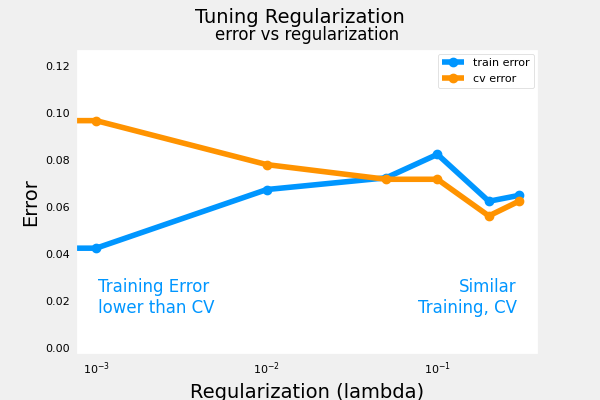

In [60]:
plot_iterate(lambdas, models, X_train, y_train, X_cv, y_cv)

As regularization is increased, the performance of the model on the training and cross-validation data sets converge. For this data set and model, lambda > 0.01 seems to be a reasonable choice.

随着正则化的增强，模型在训练集和交叉验证集上的性能趋于一致。对于这个数据集和模型来说，选择λ > 0.01似乎是一个合理的决定。

<a name="7.1"></a>
### 7.1 Test 测试
Let's try our optimized models on the test set and compare them to 'ideal' performance. 

让我们在测试集上尝试我们的优化模型，并将其与“理想”性能进行比较。

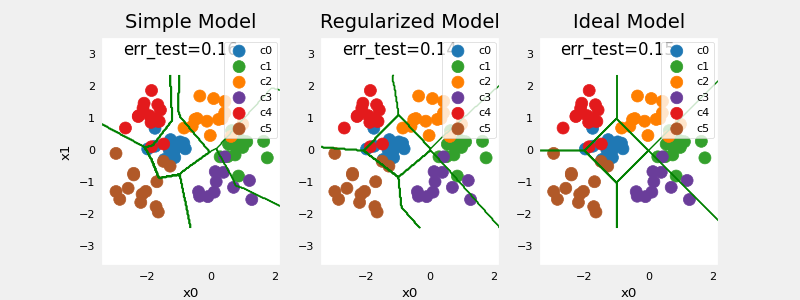

In [61]:
plt_compare(X_test,y_test, classes, model_predict_s, model_predict_r, centers)

Our test set is small and seems to have a number of outliers so classification error is high. However, the performance of our optimized models is comparable to ideal performance.

我们的测试集很小，并且似乎包含了一些离群点，所以分类错误率较高。然而，我们优化后的模型的表现与理想表现相当。

## Congratulations! 
You have become familiar with important tools to apply when evaluating your machine learning models. Namely:  
* splitting data into trained and untrained sets allows you to differentiate between underfitting and overfitting
* creating three data sets, Training, Cross-Validation and Test allows you to
    * train your parameters $W,B$ with the training set
    * tune model parameters such as complexity, regularization and number of examples with the cross-validation set
    * evaluate your 'real world' performance using the test set.
* comparing training vs cross-validation performance provides insight into a model's propensity towards overfitting (high variance) or underfitting (high bias)


## 祝贺你！
你已经熟悉了评估机器学习模型时应用的重要工具。具体来说：

* 将数据分为训练集和未训练集（如验证集或测试集），可以让你区分模型是欠拟合还是过拟合。
* 创建三个数据集：训练集、交叉验证集和测试集，可以让你：
    * 使用训练集训练模型参数 $W,B$ 
    * 使用交叉验证集调整模型参数，如复杂度、正则化程度和样本数量
    * 使用测试集评估模型在“现实世界”中的性能。
* 比较训练集和交叉验证集的性能，可以洞察模型是倾向于过拟合（高方差）还是欠拟合（高偏差）。